# TP : Prétraitement d’un Dataset en Machine Learning

## Partie 1 : Introduction au Dataset

## Importation les bibliotheque

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Charger le dataset Titanic

In [28]:
df = pd.read_excel(r"titanicDataset.xls")

## Afficher les type des donner

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB


## afficher les 5 premier ligne

In [30]:
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


## Verifie les valeurs manquantes

In [31]:
df.isnull().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

# Partie 2 : Nettoyage des Données

## Division de Dataset

In [32]:
from sklearn.model_selection import train_test_split
# Séparer les variables explicatives et la cible
X = df.drop(columns=["survived", "name", "ticket"])
y = df["survived"]
# Division du dataset : 80% Train et 20% Test
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=50,stratify=y)

## Gestion des valeurs manquantes

Identifiez les colonnes avec des valeurs manquantes.

In [33]:
# Vérifier les valeurs manquantes dans Train
print("Valeurs manquantes dans X_train :")
print(X_train.isnull().sum())
# Vérifier les valeurs manquantes dans Test
print("\nValeurs manquantes dans X_test :")
print(X_test.isnull().sum())

Valeurs manquantes dans X_train :
pclass         0
sex            0
age          213
sibsp          0
parch          0
fare           1
cabin        822
embarked       2
boat         659
body         957
home.dest    460
dtype: int64

Valeurs manquantes dans X_test :
pclass         0
sex            0
age           50
sibsp          0
parch          0
fare           0
cabin        192
embarked       0
boat         164
body         231
home.dest    104
dtype: int64


Pour les variables numériques

In [34]:
for col in ["age", "fare"]:
    mediane = X_train[col].median()
    X_train[col] = X_train[col].fillna(mediane)
    X_test[col] = X_test[col].fillna(mediane)

Pour les variables catégorielles

In [35]:
mode_embarked = X_train["embarked"].mode()[0]
X_train["embarked"] = X_train["embarked"].fillna(mode_embarked)
X_test["embarked"] = X_test["embarked"].fillna(mode_embarked)

Colonnes à supprimer

In [36]:
colonnes_a_supprimer = ["cabin", "boat", "body", "home.dest"]
X_train = X_train.drop(columns=colonnes_a_supprimer)
X_test = X_test.drop(columns=colonnes_a_supprimer)

In [37]:
print("Train :")
print(X_train.isnull().sum())

print("\nTest :")
print(X_test.isnull().sum())

Train :
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Test :
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


## Gestion des valeurs aberrantes :

détecter des valeurs aberrantes

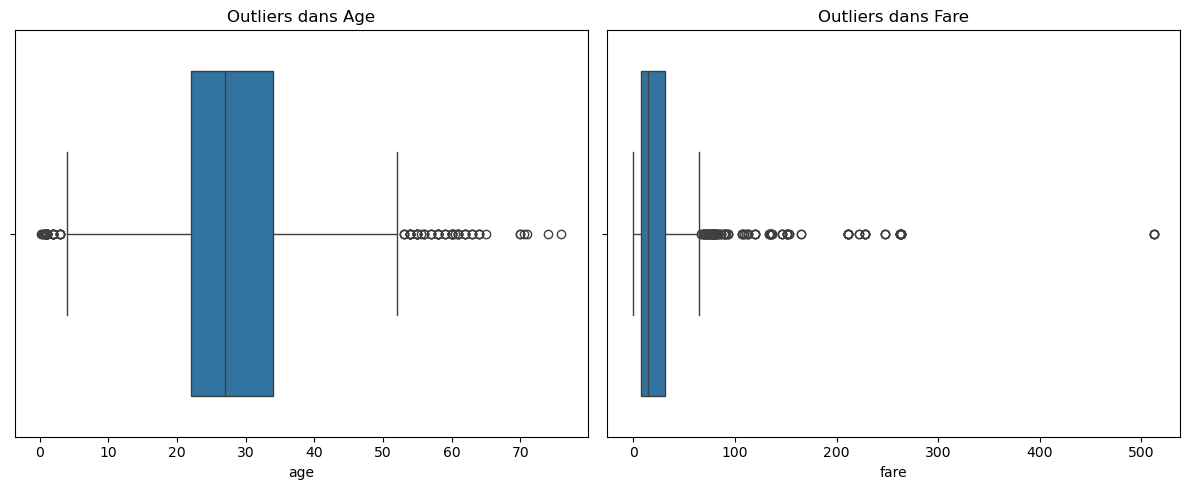

In [38]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x=X_train["age"])
plt.title("Outliers dans Age")
plt.subplot(1, 2, 2)
sns.boxplot(x=X_train["fare"])
plt.title("Outliers dans Fare")
plt.tight_layout()
plt.show()

In [39]:
for col in ["age", "fare"]:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    nb_outliers = (
        (X_train[col] < limite_inf) |
        (X_train[col] > limite_sup)
    ).sum()
    print(f"\nColonne : {col}")
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Limite inférieure :", limite_inf)
    print("Limite supérieure :", limite_sup)
    print("Nombre d'outliers :", nb_outliers)


Colonne : age
Q1 : 22.0
Q3 : 34.0
IQR : 12.0
Limite inférieure : 4.0
Limite supérieure : 52.0
Nombre d'outliers : 93

Colonne : fare
Q1 : 7.8958
Q3 : 31.0
IQR : 23.1042
Limite inférieure : -26.7605
Limite supérieure : 65.6563
Nombre d'outliers : 134


Traitement des valeurs aberrantes

In [40]:
for col in ["age", "fare"]:
    # Calcul des limites avec la méthode IQR
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    # Calcul de la médiane sur Train
    mediane = X_train[col].median()
    # Remplacer les valeurs aberrantes par la médiane
    X_train[col] = X_train[col].mask(
        (X_train[col] < limite_inf) |
        (X_train[col] > limite_sup),
        mediane
    )
    X_test[col] = X_test[col].mask(
        (X_test[col] < limite_inf) |
        (X_test[col] > limite_sup),
        mediane
    )

In [41]:
print(f"{col} : {nb_outliers} valeurs aberrantes restantes")

fare : 134 valeurs aberrantes restantes


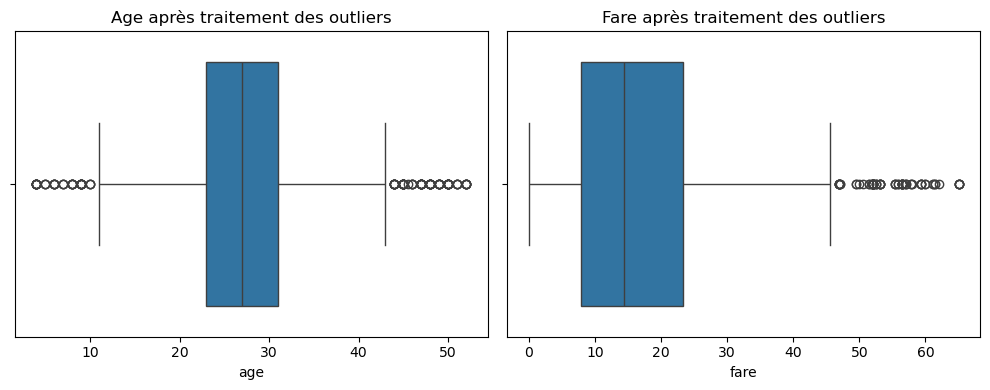

In [42]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x=X_train["age"])
plt.title("Age après traitement des outliers")
plt.subplot(1, 2, 2)
sns.boxplot(x=X_train["fare"])
plt.title("Fare après traitement des outliers")
plt.tight_layout()
plt.show()

# Partie 3 : Transformation des Données

## Encodage des variables catégorielles :

Identifiez les colonnes

In [43]:
print("Colonnes de X_train :")
print(X_train.columns.tolist())
print("\nTypes des variables :")
print(X_train.dtypes)

Colonnes de X_train :
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

Types des variables :
pclass        int64
sex          object
age         float64
sibsp         int64
parch         int64
fare        float64
embarked     object
dtype: object


l'encodage one-hot

In [44]:
X_train = pd.get_dummies(
    X_train,
    columns=["sex", "embarked"],
    dtype=int
)
X_test = pd.get_dummies(
    X_test,
    columns=["sex", "embarked"],
    dtype=int
)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_train.head()

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
1004,3,27.0,0,0,7.7875,1,0,0,1,0
315,1,21.0,0,0,26.5500,1,0,0,0,1
655,3,32.0,1,0,15.8500,0,1,0,0,1
1261,3,27.0,0,0,9.5875,1,0,0,0,1
884,3,48.0,0,0,7.8542,0,1,0,0,1


Pour les variables ordinales : La variable pclass est déjà encodée numériquement dans le dataset Titanic : 1 représente la première classe, 2 la deuxième classe et 3 la troisième classe. Il n’est donc pas nécessaire de lui appliquer un encodage supplémentaire.

In [45]:
print(X_train.head())
print(X_train.dtypes)

      pclass   age  sibsp  parch     fare  sex_female  sex_male  embarked_C  \
1004       3  27.0      0      0   7.7875           1         0           0   
315        1  21.0      0      0  26.5500           1         0           0   
655        3  32.0      1      0  15.8500           0         1           0   
1261       3  27.0      0      0   9.5875           1         0           0   
884        3  48.0      0      0   7.8542           0         1           0   

      embarked_Q  embarked_S  
1004           1           0  
315            0           1  
655            0           1  
1261           0           1  
884            0           1  
pclass          int64
age           float64
sibsp           int64
parch           int64
fare          float64
sex_female      int64
sex_male        int64
embarked_C      int64
embarked_Q      int64
embarked_S      int64
dtype: object


## Normalisation et Standardisation des données

Normalisation (Min-Max scaling)

In [46]:
from sklearn.preprocessing import MinMaxScaler
scaler_minmax = MinMaxScaler()
X_train_norm = X_train.copy()
X_test_norm = X_test.copy()
colonnes_num = ["age", "sibsp", "parch", "fare"]
X_train_norm[colonnes_num] = scaler_minmax.fit_transform(
    X_train[colonnes_num]
)
X_test_norm[colonnes_num] = scaler_minmax.transform(
    X_test[colonnes_num]
)
print(X_train_norm.head())

      pclass       age  sibsp  parch      fare  sex_female  sex_male  \
1004       3  0.479167  0.000    0.0  0.119808           1         0   
315        1  0.354167  0.000    0.0  0.408462           1         0   
655        3  0.583333  0.125    0.0  0.243846           0         1   
1261       3  0.479167  0.000    0.0  0.147500           1         0   
884        3  0.916667  0.000    0.0  0.120834           0         1   

      embarked_C  embarked_Q  embarked_S  
1004           0           1           0  
315            0           0           1  
655            0           0           1  
1261           0           0           1  
884            0           0           1  


Standardisation (Z-score)

In [47]:
from sklearn.preprocessing import StandardScaler
scaler_std = StandardScaler()
X_train_std = X_train.copy()
X_test_std = X_test.copy()
X_train_std[colonnes_num] = scaler_std.fit_transform(
    X_train[colonnes_num]
)
X_test_std[colonnes_num] = scaler_std.transform(
    X_test[colonnes_num]
)
print(X_train_std[colonnes_num].describe())

                age         sibsp         parch          fare
count  1.047000e+03  1.047000e+03  1.047000e+03  1.047000e+03
mean   8.992064e-17  5.429171e-17  3.902217e-17 -1.798413e-16
std    1.000478e+00  1.000478e+00  1.000478e+00  1.000478e+00
min   -2.644351e+00 -4.871550e-01 -4.357732e-01 -1.347980e+00
25%   -5.261656e-01 -4.871550e-01 -4.357732e-01 -7.376023e-01
50%   -8.023187e-02 -4.871550e-01 -4.357732e-01 -2.348014e-01
75%    3.657019e-01  4.806843e-01 -4.357732e-01  4.570697e-01
max    2.706854e+00  7.255560e+00  9.881540e+00  3.676783e+00


Comparaison des distributions avec des histogrammes

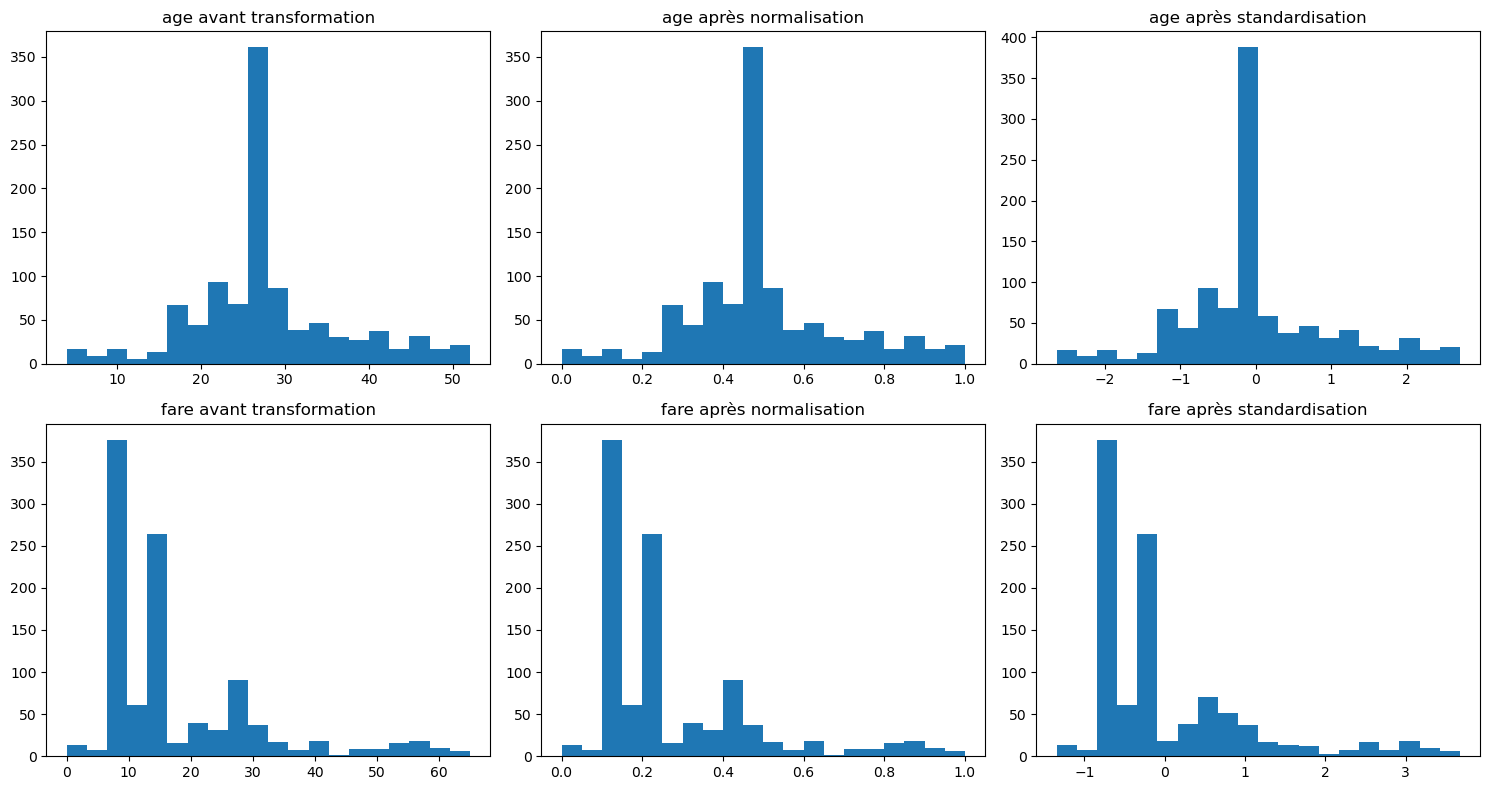

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(["age", "fare"]):
    axes[i, 0].hist(X_train[col], bins=20)
    axes[i, 0].set_title(f"{col} avant transformation")
    axes[i, 1].hist(X_train_norm[col], bins=20)
    axes[i, 1].set_title(f"{col} après normalisation")
    axes[i, 2].hist(X_train_std[col], bins=20)
    axes[i, 2].set_title(f"{col} après standardisation")
plt.tight_layout()
plt.show()

## Partie 4 : Gestion des Données Déséquilibrées

Identification du déséquilibre des classes

In [49]:
print(y_train.value_counts())

survived
0    647
1    400
Name: count, dtype: int64


In [50]:
# les pourcentage
print(y_train.value_counts(normalize=True) * 100)

survived
0    61.795606
1    38.204394
Name: proportion, dtype: float64


Gestion du déséquilibre Sous-échantillonnage (undersampling)

In [51]:
from imblearn.under_sampling import RandomUnderSampler
under = RandomUnderSampler(random_state=42)
X_under, y_under = under.fit_resample(X_train, y_train)
print("Après undersampling :")
print(y_under.value_counts())

Après undersampling :
survived
0    400
1    400
Name: count, dtype: int64


Gestion du déséquilibre Sur-échantillonnage (oversampling)

In [52]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
print("Après SMOTE :")
print(y_smote.value_counts())

Après SMOTE :
survived
1    647
0    647
Name: count, dtype: int64


## -------------------------------------------FIN-------------------------------------------